# Funnels and Markov chains: transition counts

A user session is a path through states: landing → product → cart → checkout → purchase, with returns, repeats
and exits along the way. Model it as a first-order Markov chain with transition matrix $P$: the next state
depends only on the current one. The likelihood of a set of observed paths is

$$\prod_{\text{paths}}\prod_{t} P_{s_{t-1}, s_t} = \prod_{i,j} P_{ij}^{N_{ij}},$$

so the matrix of transition counts $N_{ij}$ is sufficient, however many sessions there are and however long
they ran. Each row is a multinomial, $N_{i\cdot} \sim \text{Multinomial}(n_i, P_{i\cdot})$, and a Dirichlet
prior per row is conjugate.

A *funnel* is the special case with no returns or repeats: from each stage a user either advances one stage
or leaves. Each row then has two outcomes, the multinomials become binomials, $n_{k+1} \sim
\text{Binomial}(n_k, p_k)$, and the sufficient statistic is the head-count reaching each stage. Product
dashboards usually report these head-counts, so they are often the only data available.

The notebook shows what the chain is used for (the probability that a session ends in a purchase, and which
step is worth improving), then compares raw-row and count fits for the chain and for a cohort funnel.

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
import arviz as az
import matplotlib.pyplot as plt

rng = np.random.default_rng(404)
SAMPLE_KW = dict(nuts_sampler="nutpie", draws=1000, tune=1000, chains=4, progressbar=False)
TIMINGS = []


def timed_fit(model, label, n_rows, case, kind, **kw):
    t0 = time.perf_counter()
    idata = pm.sample(model=model, random_seed=rng, **{**SAMPLE_KW, **kw})
    secs = time.perf_counter() - t0
    ess = float(az.summary(idata)["ess_bulk"].min())
    TIMINGS.append({"case": case, "kind": kind, "model": label, "rows": int(n_rows),
                    "wall_s": round(secs, 2), "min_ess_per_s": round(ess / secs, 1)})
    return idata


def save_timings(name):
    Path("timings").mkdir(exist_ok=True)
    Path(f"timings/{name}.json").write_text(json.dumps(TIMINGS, indent=1))
    return pd.DataFrame(TIMINGS).drop(columns="case")

## Sessions as a Markov chain

Four transient states, two absorbing ones (purchase, exit), and two traffic sources with different behaviour.
Some moves are impossible (landing → cart, for example), and the prior respects that: each row has a
Dirichlet over its allowed destinations only. We simulate 20,000 sessions and keep every transition with its
session id.

In [2]:
STATES = ["landing", "product", "cart", "checkout", "purchase", "exit"]
SOURCES = ["paid", "organic"]
TRANSIENT = 4
ALLOWED = {0: [1, 5], 1: [0, 1, 2, 5], 2: [1, 2, 3, 5], 3: [2, 4, 5]}
P_true = np.array([
    [[0.00, 0.55, 0.00, 0.00, 0.00, 0.45],
     [0.20, 0.35, 0.18, 0.00, 0.00, 0.27],
     [0.00, 0.30, 0.05, 0.45, 0.00, 0.20],
     [0.00, 0.00, 0.15, 0.00, 0.60, 0.25]],
    [[0.00, 0.65, 0.00, 0.00, 0.00, 0.35],
     [0.15, 0.40, 0.20, 0.00, 0.00, 0.25],
     [0.00, 0.25, 0.05, 0.50, 0.00, 0.20],
     [0.00, 0.00, 0.10, 0.00, 0.70, 0.20]],
])
n_sess = 20_000
source = rng.integers(0, 2, n_sess)

rec = {"session": [], "step": [], "source": [], "from": [], "to": []}
state = np.zeros(n_sess, int)
active = np.ones(n_sess, bool)
step = 0
while active.any():
    idx = np.flatnonzero(active)
    probs = P_true[source[idx], state[idx]]
    nxt = (probs.cumsum(1) > rng.random(len(idx))[:, None]).argmax(1)
    for key, val in [("session", idx), ("step", np.full(len(idx), step)), ("source", source[idx]),
                     ("from", state[idx]), ("to", nxt)]:
        rec[key].append(val)
    state[idx] = nxt
    active[idx] = nxt < TRANSIENT
    step += 1
transitions = (pd.DataFrame({k: np.concatenate(v) for k, v in rec.items()})
               .sort_values(["session", "step"]).reset_index(drop=True))

N = np.zeros((2, TRANSIENT, len(STATES)), int)
np.add.at(N, (transitions.source, transitions["from"], transitions.to), 1)
print(f"{n_sess:,} sessions -> {len(transitions):,} transitions -> {sum(len(a) for a in ALLOWED.values()) * 2} counts")
pd.DataFrame(N[0], index=STATES[:TRANSIENT], columns=STATES)

20,000 sessions -> 58,669 transitions -> 26 counts


,landing,product,cart,checkout,purchase,exit
landing,0,6658,0,0,0,5551
product,2261,3934,2041,0,0,3008
cart,0,652,119,1074,0,488
checkout,0,0,173,0,633,268


## The algebra of an absorbing chain

Order the states with the four transient states first, numbered 1 (landing), 2 (product), 3 (cart) and
4 (checkout), and the two absorbing states last, $b$ (purchase) and $x$ (exit). The transition matrix then has
the block form

$$
P = \begin{pmatrix} Q & R \\ 0 & I \end{pmatrix},
$$

where $Q$ ($4 \times 4$) holds the moves between transient states, $R$ ($4 \times 2$) the moves from a transient
state into an absorbing one, and the identity says that a session that has purchased or exited stays there. For
this chain, with zeros at the impossible moves,

$$
Q = \begin{pmatrix}
0 & q_{12} & 0 & 0 \\
q_{21} & q_{22} & q_{23} & 0 \\
0 & q_{32} & q_{33} & q_{34} \\
0 & 0 & q_{43} & 0
\end{pmatrix},
\qquad
R = \begin{pmatrix}
0 & r_{1x} \\
0 & r_{2x} \\
0 & r_{3x} \\
r_{4b} & r_{4x}
\end{pmatrix},
$$

and each row of $(Q \;\, R)$ sums to one. Three quantities follow.

**Expected visits.** Entry $(i, j)$ of $Q^k$ is the probability that a session starting in state $i$ is in transient
state $j$ after $k$ steps, not yet absorbed. Summing over all $k$ gives the expected number of visits to $j$:

$$
N = \sum_{k=0}^{\infty} Q^k = I + Q + Q^2 + \dots = (I - Q)^{-1}.
$$

The series converges because every transient state can reach exit, so $Q^k \to 0$. Multiplying the sum by
$(I - Q)$ cancels every term but $I$, which gives the inverse. $N$ is called the **fundamental matrix**. Its first
row counts every visit a landing-page session makes, return trips included.

**Absorption probabilities.** A session ends in absorbing state $a$ when, on one of its visits to some transient
state $j$, it moves from $j$ to $a$. Summing over $j$ the expected visits times that move's probability,

$$
B = N R, \qquad B_{ia} = \sum_j N_{ij} R_{ja}.
$$

Each row of $B$ sums to one. Only checkout leads to purchase, so the purchase probability for a landing-page
session is $B_{1b} = N_{14}\, r_{4b}$: expected checkout visits times the probability that a checkout visit ends
in purchase.

**The forward-only product.** Multiplying the forward step rates, $q_{12}\,q_{23}\,q_{34}\,r_{4b}$, is a single
term of the series: the session that goes straight through in four steps. It ignores every path with a loop or a
return, so it is smaller than $B_{1b}$.

**Which step to improve.** Moving $\delta$ of probability from exit to the step $i \to j$ changes the matrix to
$Q' = Q + \delta\, e_i e_j^\top$ (or $R$ gains $\delta$ in column $b$ if $j$ is purchase) and $R' = R - \delta\, e_i e_x^\top$,
where $e_i$ is the $i$-th unit vector. The new purchase probability is $B'_{1b} = \big[(I - Q')^{-1} R'\big]_{1b}$.
Because $d(I-Q)^{-1} = N\,dQ\,N$, to first order

$$
\Delta B_{1b} \approx \delta\, N_{1i}\, B_{jb},
$$

expected visits to the state being improved, times $\delta$, times the purchase probability from the new
destination ($B_{bb} = 1$). A step is worth improving when it is visited often and leads somewhere that converts.

All of these are computed inside the model below with `pt.linalg.inv`, as deterministic functions of $P$. Each
posterior draw of $P$ gives a draw of $N$, $B$, the forward-only product and every what-if change, so their
posteriors come out of the sampler directly.

## Raw transitions vs counts

The raw-row model adds each transition's $\log P_{\text{from},\text{to}}$ with `pm.Potential`. (Passing the
full row $P_{\text{from},\cdot}$ to `pm.Categorical` per transition is the same likelihood but about six times
slower, because it builds a transitions × states array at every gradient step.) The compressed model has one
multinomial per row of the count matrix. Both share the prior and the deterministic quantities.

In [3]:
EDGES = [(0, 1), (1, 2), (2, 3), (3, 4)]
EDGE_NAMES = [f"{STATES[i]} → {STATES[j]}" for i, j in EDGES]
STEP = 0.05                                     # what-if: probability moved from exit to the step
coords = {"source": SOURCES, "from": STATES[:TRANSIENT], "to": STATES, "visit": STATES[:TRANSIENT],
          "absorbing": STATES[TRANSIENT:], "edge": EDGE_NAMES}


def absorption(P):
    """Fundamental matrix N = (I - Q)^-1 and absorption probabilities B = N R, per source."""
    Q, R = P[:, :, :TRANSIENT], P[:, :, TRANSIENT:]
    Nf = pt.linalg.inv(pt.eye(TRANSIENT) - Q)
    return Nf, Nf @ R


def transition_prior():
    full = pt.zeros((2, TRANSIENT, len(STATES)))
    rows = {}
    for i, allowed in ALLOWED.items():
        rows[i] = pm.Dirichlet(f"P_{STATES[i]}", a=np.ones(len(allowed)), shape=(2, len(allowed)))
        full = pt.set_subtensor(full[:, i, allowed], rows[i])
    P = pm.Deterministic("P", full, dims=("source", "from", "to"))

    # The algebra above, evaluated for every posterior draw.
    Nf, B = absorption(P)
    pm.Deterministic("visits", Nf, dims=("source", "from", "visit"))
    pm.Deterministic("absorption", B, dims=("source", "from", "absorbing"))
    p_purchase = pm.Deterministic("p_purchase", B[:, 0, 0], dims="source")
    pm.Deterministic("forward_only", P[:, 0, 1] * P[:, 1, 2] * P[:, 2, 3] * P[:, 3, 4], dims="source")
    changes = []
    for i, j in EDGES:
        P2 = pt.inc_subtensor(P[:, i, j], STEP)                 # more probability on the step i -> j
        P2 = pt.inc_subtensor(P2[:, i, len(STATES) - 1], -STEP)  # taken from i -> exit
        changes.append(absorption(P2)[1][:, 0, 0] - p_purchase)
    pm.Deterministic("whatif", pt.stack(changes, axis=-1), dims=("source", "edge"))
    return P, rows


with pm.Model(coords=coords) as mc_full:
    P, _ = transition_prior()
    pm.Potential("transitions_loglik", pm.math.log(
        P[transitions.source.values, transitions["from"].values, transitions.to.values]).sum())

with pm.Model(coords=coords) as mc_suff:
    P, rows = transition_prior()
    for i, allowed in ALLOWED.items():
        Ni = N[:, i][:, allowed]
        pm.Multinomial(f"N_{STATES[i]}", n=Ni.sum(-1), p=rows[i], observed=Ni)

idata_mf = timed_fit(mc_full, "Markov: log P per transition", len(transitions), "Markov chain", "raw")
idata_ms = timed_fit(mc_suff, "Markov: Multinomial on N_ij", 2 * TRANSIENT, "Markov chain", "compressed")

NUTS[nutpie]: [P_landing, P_product, P_cart, P_checkout]
/Users/nathanielforde/Documents/Github/bayesian_causal_inference/.venv/lib/python3.13/site-packages/arviz_stats/base/diagnostics.py:90: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/Users/nathanielforde/Documents/Github/bayesian_causal_inference/.venv/lib/python3.13/site-packages/arviz_stats/base/diagnostics.py:313: RuntimeWarning: invalid value encountered in scalar divide
  varsd = varvar / evar / 4
/Users/nathanielforde/Documents/Github/bayesian_causal_inference/.venv/lib/python3.13/site-packages/arviz_stats/base/diagnostics.py:313: RuntimeWarning: invalid value encountered in scalar divide
  varsd = varvar / evar / 4
/Users/nathanielforde/Documents/Github/bayesian_causal_inference/.venv/lib/python3.13/site-packages/arviz_stats/base/diagnostics.py:313: RuntimeWarning: invalid value encountered in scalar divide
  varsd = varvar / 

## The fitted chain

The heatmap shows the posterior transition probabilities with 89% intervals. Grey cells are impossible moves.
The back-edges (product → landing, cart → product, checkout → cart) are what make this a chain rather than a
funnel: a sizeable share of sessions moves backwards before converting or leaving.

In [4]:
post_ms = idata_ms.posterior
flat = lambda var: post_ms[var].values.reshape((-1,) + post_ms[var].shape[2:])
P_draws = flat("P")

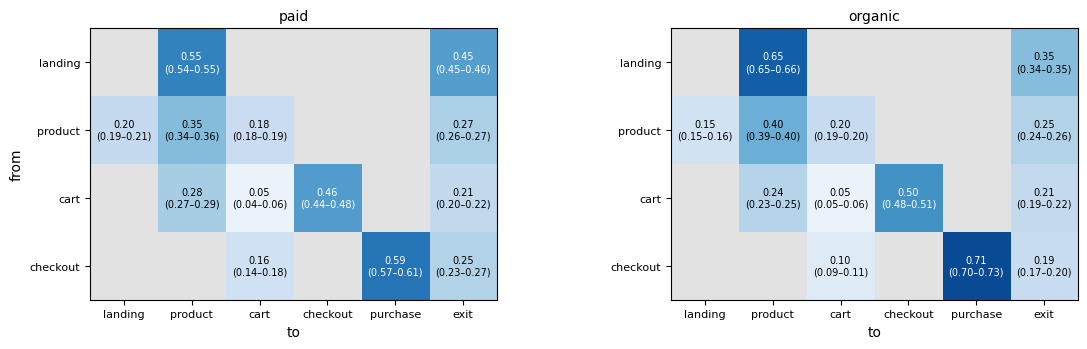

In [5]:
#| label: fig-funnel-matrix
#| fig-cap: "Posterior mean transition probabilities (89% interval) from the transition-count fit, by traffic source. Grey cells are impossible moves."
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
mask = np.ones((TRANSIENT, len(STATES)), bool)
for i, allowed in ALLOWED.items():
    mask[i, allowed] = False
for s, ax in enumerate(axes):
    mean = P_draws[:, s].mean(0)
    lo, hi = np.quantile(P_draws[:, s], [0.055, 0.945], 0)
    ax.imshow(np.ma.masked_where(mask, mean), cmap="Blues", vmin=0, vmax=0.8)
    ax.imshow(np.ma.masked_where(~mask, np.ones_like(mean)), cmap="Greys", vmin=0, vmax=5)
    for i in range(TRANSIENT):
        for j in range(len(STATES)):
            if not mask[i, j]:
                ax.text(j, i, f"{mean[i, j]:.2f}\n({lo[i, j]:.2f}–{hi[i, j]:.2f})", ha="center", va="center",
                        fontsize=7, color="white" if mean[i, j] > 0.45 else "black")
    ax.set_xticks(range(len(STATES)), STATES, fontsize=8)
    ax.set_yticks(range(TRANSIENT), STATES[:TRANSIENT], fontsize=8)
    ax.set_xlabel("to")
    ax.set_title(SOURCES[s], fontsize=10)
axes[0].set_ylabel("from")
plt.tight_layout()
plt.show()

## Expected visits, purchase probability and which step to improve

These are the posteriors of the deterministic quantities defined above: the first row of $N$, the purchase
probability $B_{1b}$ against the forward-only product, and the what-if changes $\Delta B_{1b}$ with $\delta = 0.05$.

In [6]:
visits, p_purchase, forward = flat("visits"), flat("p_purchase"), flat("forward_only")
whatif = flat("whatif")                                                 # (draw, source, edge)
pd.DataFrame({"P(purchase) = [(I − Q)⁻¹ R]₁b": p_purchase.mean(0), "forward-only product": forward.mean(0),
              "expected checkout visits N₁₄": visits[:, :, 0, 3].mean(0)}, index=SOURCES).round(4)

,P(purchase) = [(I − Q)⁻¹ R]₁b,forward-only product,expected checkout visits N₁₄
paid,0.0636,0.0268,0.1079
organic,0.1141,0.0459,0.1599


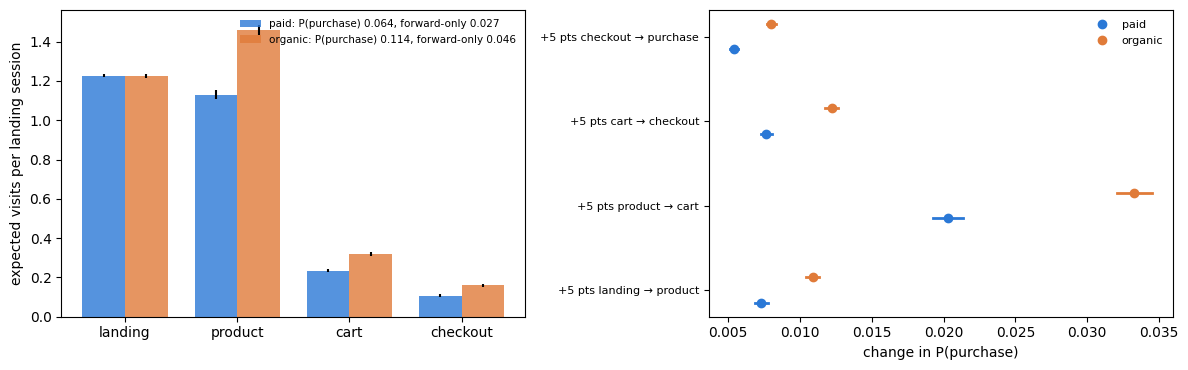

In [7]:
#| label: fig-funnel-whatif
#| fig-cap: "Left: expected visits to each state per landing-page session, the first row of the fundamental matrix (posterior mean and 89% interval); the legend compares the purchase probability from the chain with the forward-only product. Right: posterior change in the purchase probability from moving 5 percentage points from exit to each forward step (mean and 89% interval), computed exactly inside the model."
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
w = 0.38
cols = ["#2a78d6", "#e07b39"]
for s in range(2):
    v = visits[:, s, 0, :]
    m = v.mean(0)
    lo, hi = np.quantile(v, [0.055, 0.945], 0)
    ax.bar(np.arange(TRANSIENT) + (s - 0.5) * w, m, w, yerr=[m - lo, hi - m], color=cols[s], alpha=0.8,
           label=f"{SOURCES[s]}: P(purchase) {p_purchase[:, s].mean():.3f}, forward-only {forward[:, s].mean():.3f}")
ax.set_xticks(range(TRANSIENT), STATES[:TRANSIENT])
ax.set_ylabel("expected visits per landing session")
ax.legend(frameon=False, fontsize=7.5, loc="upper right")
ax = axes[1]
for s in range(2):
    for r, name in enumerate(EDGE_NAMES):
        d = whatif[:, s, r]
        y0 = r + (s - 0.5) * 0.3
        ax.plot(np.quantile(d, [0.055, 0.945]), [y0, y0], color=cols[s], lw=2)
        ax.plot(d.mean(), y0, "o", color=cols[s], label=SOURCES[s] if r == 0 else None)
ax.set_yticks(range(len(EDGE_NAMES)), [f"+5 pts {n}" for n in EDGE_NAMES], fontsize=8)
ax.set_xlabel("change in P(purchase)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

The first-order formula explains the ranking. For each step, compare the exact change with
$\delta\, N_{1i}\, B_{jb}$, using posterior means:

In [8]:
B_draws = flat("absorption")
rows_ = []
for e, (i, j) in enumerate(EDGES):
    for s in range(2):
        B_jb = 1.0 if j == TRANSIENT else B_draws[:, s, j, 0].mean()
        rows_.append({"step": EDGE_NAMES[e], "source": SOURCES[s],
                      "visits to i, N₁ᵢ": visits[:, s, 0, i].mean(), "B_jb": B_jb,
                      "δ N₁ᵢ B_jb": STEP * visits[:, s, 0, i].mean() * B_jb,
                      "exact change": whatif[:, s, e].mean()})
pd.DataFrame(rows_).set_index(["step", "source"]).round(4)

visits to i, N₁ᵢ    B_jb  δ N₁ᵢ B_jb  \
step                source                                          
landing → product   paid               1.2273  0.1166      0.0072   
                    organic            1.2257  0.1745      0.0107   
product → cart      paid               1.1302  0.3471      0.0196   
                    organic            1.4585  0.4427      0.0323   
cart → checkout     paid               0.2347  0.6451      0.0076   
                    organic            0.3211  0.7568      0.0121   
checkout → purchase paid               0.1079  1.0000      0.0054   
                    organic            0.1599  1.0000      0.0080   

                             exact change  
step                source                 
landing → product   paid           0.0073  
                    organic        0.0109  
product → cart      paid           0.0203  
                    organic        0.0333  
cart → checkout     paid           0.0076  
                    organic        0.0122  
checkout → purchase paid           0.0054  
                    organic        0.0080

Improving checkout → purchase is the smallest lever, even though it is the last step: checkout is visited only
about 0.1 times per landing session. Product pages are visited more than once per session on average, and a
session that reaches the cart goes on to buy between a third and a half of the time, so product → cart is worth
about four times as much.

## Does the Markov assumption hold?

The counts $N_{ij}$ are sufficient only if the chain is first-order. The raw sessions can check this before
we compress. Two checks:

1. **Second-order counts.** If the chain is first-order, the probability of moving from cart to checkout should
   not depend on where the session was before the cart.
2. **Session length.** Simulate sessions from posterior draws of $P$ and compare their length distribution with
   the observed one.

In this simulation the chain is first-order by construction, so both checks should pass. In real data, these
are the checks that justify the compression.

In [9]:
transitions["prev"] = transitions.groupby("session")["from"].shift(1)
from_cart = transitions[(transitions["from"] == 2) & transitions.prev.notna()]
second = from_cart.assign(to_checkout=(from_cart.to == 3)).groupby("prev").to_checkout.agg(["sum", "size"])
second.index = [STATES[int(i)] for i in second.index]

obs_len = transitions.groupby("session").size()
L = np.arange(1, 16)
obs_share = np.array([(obs_len == l).mean() for l in L])


def simulate_lengths(P, n):
    st, length, act = np.zeros(n, int), np.zeros(n, int), np.ones(n, bool)
    src = rng.integers(0, 2, n)
    while act.any():
        idx = np.flatnonzero(act)
        nxt = (P[src[idx], st[idx]].cumsum(1) > rng.random(len(idx))[:, None]).argmax(1)
        st[idx], length[idx] = nxt, length[idx] + 1
        act[idx] = nxt < TRANSIENT
    return length


ppc = np.array([[(lens == l).mean() for l in L] for lens in
                (simulate_lengths(P_draws[d], 2000) for d in rng.choice(len(P_draws), 200, replace=False))])

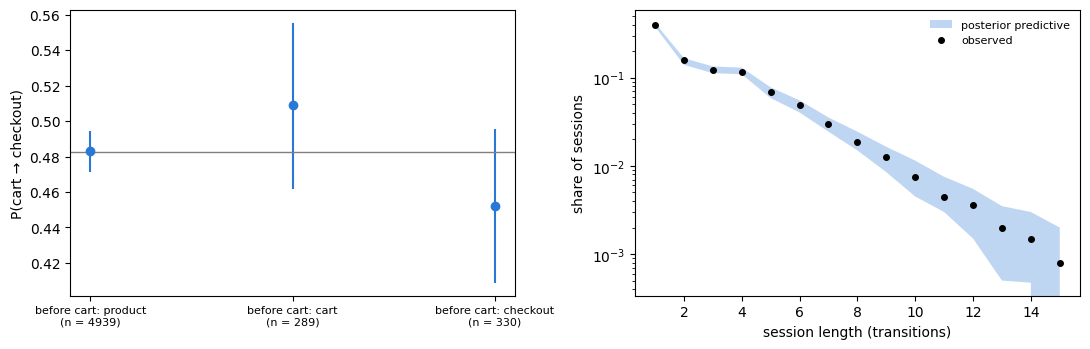

In [10]:
#| label: fig-funnel-check
#| fig-cap: "Checks of the first-order Markov assumption on the raw sessions. Left: probability of moving from cart to checkout, split by the state before the cart (Beta posterior, 89% interval); the grey line is the pooled rate. Right: observed session lengths (points) against lengths simulated from 200 posterior draws of P (89% band)."
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
for r, (h, row) in enumerate(second.iterrows()):
    dr = rng.beta(1 + row["sum"], 1 + row["size"] - row["sum"], 20_000)
    ax.errorbar(r, dr.mean(), yerr=[[dr.mean() - np.quantile(dr, .055)], [np.quantile(dr, .945) - dr.mean()]],
                fmt="o", color="#2a78d6")
ax.axhline((from_cart.to == 3).mean(), color="grey", lw=1)
ax.set_xticks(range(len(second)), [f"before cart: {h}\n(n = {int(n)})" for h, n in zip(second.index, second["size"])], fontsize=8)
ax.set_ylabel("P(cart → checkout)")
ax = axes[1]
lo, hi = np.quantile(ppc, [0.055, 0.945], 0)
ax.fill_between(L, lo, hi, color="#2a78d6", alpha=0.3, lw=0, label="posterior predictive")
ax.plot(L, obs_share, "ko", ms=4, label="observed")
ax.set_yscale("log")
ax.set_xlabel("session length (transitions)")
ax.set_ylabel("share of sessions")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

## A cohort funnel

12 weekly sign-up cohorts pass through visit → sign-up → activate → pay. This is the chain above with every
back-edge and repeat removed: from each stage a user advances or leaves. Step conversion rates vary across
cohorts, so we pool them on the logit scale with a hierarchical prior. The raw data is one Bernoulli per user
per stage reached; the compressed data is a 12 × 4 table of head-counts.

In [11]:
n_coh, steps = 12, ["sign-up", "activate", "pay"]
mu_true, sd_true = np.array([-1.2, 0.3, -1.0]), np.array([0.15, 0.25, 0.20])
logit_p = mu_true[:, None] + sd_true[:, None] * rng.normal(size=(3, n_coh))
p_true = 1 / (1 + np.exp(-logit_p))
visits = rng.integers(1_500, 3_500, n_coh)

rows_ = []
reached = [np.repeat(np.arange(n_coh), visits)]
for k in range(3):
    coh = reached[-1]
    y = rng.binomial(1, p_true[k, coh])
    rows_.append(pd.DataFrame({"cohort": coh, "step": k, "y": y}))
    reached.append(coh[y == 1])
users = pd.concat(rows_, ignore_index=True)

heads = np.array([np.bincount(r, minlength=n_coh) for r in reached])   # (stage, cohort) head-counts
print(f"{visits.sum():,} visitors -> {len(users):,} user-step rows -> {heads.size} head-counts")
pd.DataFrame(heads[:, :6], index=["visit"] + steps, columns=[f"wk{c + 1}" for c in range(6)])

33,405 visitors -> 45,181 user-step rows -> 48 head-counts


,wk1,wk2,wk3,wk4,wk5,wk6
visit,3181,1996,1767,3426,3195,1779
sign-up,721,438,452,722,838,420
activate,415,301,215,317,376,222
pay,127,80,64,62,92,56


In [12]:
fcoords = {"step": steps, "cohort": np.arange(n_coh)}


def funnel_prior():
    mu = pm.Normal("mu", 0, 1.5, dims="step")
    sd = pm.HalfNormal("sd", 0.5, dims="step")
    z = pm.Normal("z", 0, 1, dims=("step", "cohort"))
    return pm.Deterministic("p", pm.math.invlogit(mu[:, None] + sd[:, None] * z), dims=("step", "cohort"))


with pm.Model(coords=fcoords) as fun_full:
    p = funnel_prior()
    pm.Bernoulli("y", p=p[users.step.values, users.cohort.values], observed=users.y.values)

with pm.Model(coords=fcoords) as fun_suff:
    p = funnel_prior()
    pm.Binomial("n_next", n=heads[:-1], p=p, observed=heads[1:])

idata_ff = timed_fit(fun_full, "Funnel: Bernoulli per user-step", len(users), "Funnel", "raw")
idata_fs = timed_fit(fun_suff, "Funnel: Binomial on head-counts", heads[:-1].size, "Funnel", "compressed")

NUTS[nutpie]: [mu, sd, z]
NUTS[nutpie]: [mu, sd, z]


The end-to-end conversion of a cohort is the product of its step conversions. The hierarchical prior pulls
each cohort's step rates toward the population mean, more strongly for small cohorts and noisy steps. The
figure shows the end-to-end rate per cohort and, for the last step, how far each cohort's estimate moves from
its raw ratio.

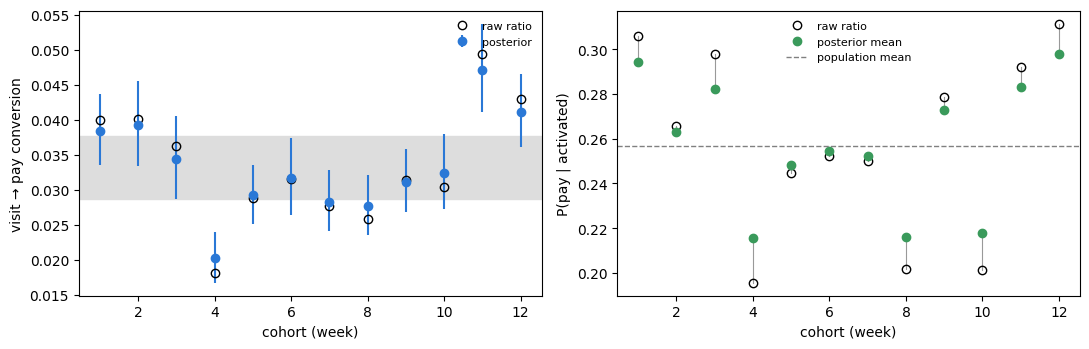

In [13]:
#| label: fig-funnel-cohorts
#| fig-cap: "Left: end-to-end conversion (visit to pay) per weekly cohort, posterior mean and 89% interval from the head-count fit, with raw ratios as open circles and the population-level rate as the grey band. Right: the activate → pay step per cohort, raw ratio (open) and posterior mean (filled), joined by a line to show partial pooling."
pf = idata_fs.posterior
p_draws = pf["p"].values.reshape(-1, 3, n_coh)
e2e = p_draws.prod(1)
pop = (1 / (1 + np.exp(-pf["mu"].values.reshape(-1, 3)))).prod(1)
wk = np.arange(1, n_coh + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
ax.axhspan(*np.quantile(pop, [0.055, 0.945]), color="#dddddd")
lo, hi = np.quantile(e2e, [0.055, 0.945], 0)
ax.errorbar(wk, e2e.mean(0), yerr=[e2e.mean(0) - lo, hi - e2e.mean(0)], fmt="o", color="#2a78d6", label="posterior")
ax.plot(wk, heads[3] / heads[0], "o", mfc="none", color="k", label="raw ratio")
ax.set_xlabel("cohort (week)")
ax.set_ylabel("visit → pay conversion")
ax.legend(frameon=False, fontsize=8)
ax = axes[1]
raw_pay = heads[3] / heads[2]
post_pay = p_draws[:, 2].mean(0)
for c in range(n_coh):
    ax.plot([wk[c], wk[c]], [raw_pay[c], post_pay[c]], color="#999999", lw=0.8)
ax.plot(wk, raw_pay, "o", mfc="none", color="k", label="raw ratio")
ax.plot(wk, post_pay, "o", color="#3a9a5b", label="posterior mean")
ax.axhline(1 / (1 + np.exp(-pf["mu"].sel(step="pay").values.mean())), color="grey", lw=1, ls="--", label="population mean")
ax.set_xlabel("cohort (week)")
ax.set_ylabel("P(pay | activated)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

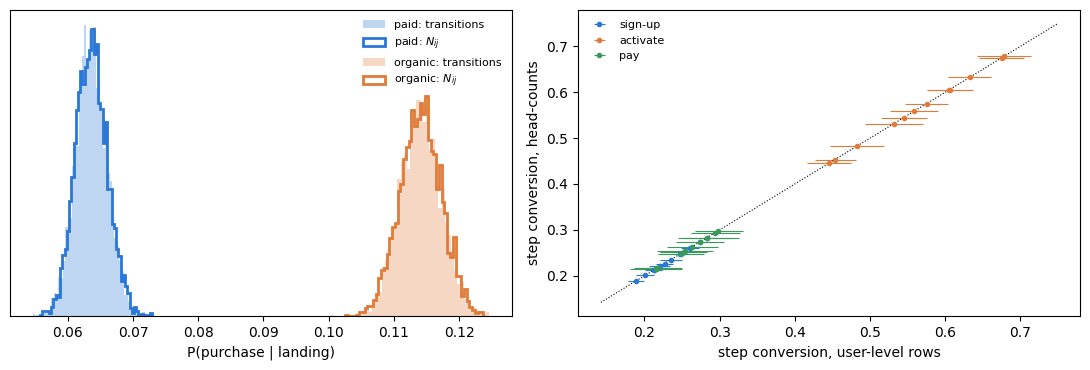

In [14]:
#| label: fig-funnel-equiv
#| fig-cap: "Left: posterior probability that a landing-page session ends in purchase, by traffic source, from every transition (filled) and from the transition-count matrix (line). Right: per-cohort step conversion posterior means from user-level rows against head-counts, with 89% intervals from the user-level fit; points on the diagonal mean the two fits agree."
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
for s, col in zip(SOURCES, cols):
    ax.hist(idata_mf.posterior["p_purchase"].sel(source=s).values.ravel(), bins=50, density=True,
            alpha=0.3, color=col, label=f"{s}: transitions")
    ax.hist(idata_ms.posterior["p_purchase"].sel(source=s).values.ravel(), bins=50, density=True,
            histtype="step", lw=2, color=col, label=f"{s}: $N_{{ij}}$")
ax.set_yticks([])
ax.set_xlabel("P(purchase | landing)")
ax.legend(frameon=False, fontsize=8)
ax = axes[1]
pfu, psu = idata_ff.posterior["p"], idata_fs.posterior["p"]
for k, col in zip(steps, ["#2a78d6", "#e07b39", "#3a9a5b"]):
    x, yv = pfu.sel(step=k), psu.sel(step=k)
    xm, ym = x.mean(("chain", "draw")), yv.mean(("chain", "draw"))
    xlo, xhi = x.quantile([0.055, 0.945], ("chain", "draw"))
    ax.errorbar(xm, ym, xerr=[xm - xlo, xhi - xm], fmt="o", ms=3, lw=0.8, color=col, label=k)
lims = [float(pfu.min()), float(pfu.max())]
ax.plot(lims, lims, "k:", lw=0.8)
ax.set_xlabel("step conversion, user-level rows")
ax.set_ylabel("step conversion, head-counts")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

In [15]:
#| label: tbl-funnel-speed
#| tbl-cap: "Transition-level and user-level likelihoods against their count summaries. The last column gives the posterior mean purchase probability (paid / organic) for the two Markov fits."
speed = save_timings("04_funnels_markov_chains")
speed["P(purchase) paid / organic"] = [
    " / ".join(f"{float(i.posterior['p_purchase'].sel(source=s).mean()):.4f}" for s in SOURCES)
    for i in (idata_mf, idata_ms)] + ["", ""]
speed

,kind,model,rows,wall_s,min_ess_per_s,P(purchase) paid / organic
0,raw,Markov: log P per transition,58669,17.34,178.0,0.0636 / 0.1141
1,compressed,Markov: Multinomial on N_ij,8,3.76,722.4,0.0636 / 0.1141
2,raw,Funnel: Bernoulli per user-step,45181,15.31,38.3,
3,compressed,Funnel: Binomial on head-counts,36,1.28,416.1,


## What compression gives up

- **The order of states within a session.** $N_{ij}$ is sufficient only for a first-order chain. If the next step
  depends on more history, check with second-order counts $N_{hij}$ (still a count tensor, just larger), as above.
- **Session-level heterogeneity.** A random effect shared by a user's transitions makes transitions from different
  users no longer interchangeable, and breaks sufficiency in the same way frailty does in survival models.
- **Per-user covariates** must be categorical to stratify the count tensor (source, device, region).